# Análise de Fourier do Movimento de um Pêndulo Simples

## Membros : Lucca Quaresma, Henrique Couri e Vitto Baroni
## 1. Modelagem da Equação Diferencial e Dependência do Período com a Amplitude

### 1.1 A Equação Diferencial Não Linear
Considerando um pêndulo simples de massa $m$ e comprimento $L$, sujeito à aceleração da gravidade $g$, a aplicação da Segunda Lei de Newton para o movimento rotacional fornece a seguinte Equação Diferencial Ordinária (EDO) de segunda ordem:

$$\frac{d^2\theta}{dt^2} + \omega_0^2 \sin\theta = 0$$

Onde $\theta(t)$ representa o deslocamento angular em relação à posição de equilíbrio vertical e $\omega_0 = \sqrt{\frac{g}{L}}$ é a frequência natural do sistema para oscilações de pequena amplitude.

### 1.2 O Comportamento do Período em Grandes Amplitudes
Para pequenas amplitudes ($\theta_0 \le 10^\circ$), adota-se a aproximação de Taylor $\sin\theta \approx \theta$. Sob essa hipótese, a equação assume a forma do Movimento Harmônico Simples (MHS), produzindo um período constante e independente da amplitude inicial $\theta_0$:

$$T_0 = \frac{2\pi}{\omega_0} = 2\pi\sqrt{\frac{L}{g}}$$

Quando a amplitude de oscilação aumenta ($\theta_0 > 20^\circ$), o termo não linear $\sin\theta$ passa a ser relevante. A força restauradora é menor do que seria no caso linear, o que desacelera a taxa de variação angular e **aumenta o período de oscilação $T$**. O período exato passa a depender de uma integral elíptica completa de primeira espécie $K(k)$:

$$T(\theta_0) = T_0 \cdot \frac{2}{\pi} K\left(\sin\frac{\theta_0}{2}\right)$$

Aproximando essa integral via expansão em série de potências, obtemos a relação entre o período real $T$ e a amplitude inicial $\theta_0$:

$$T(\theta_0) \approx T_0 \left( 1 + \frac{1}{16}\theta_0^2 + \frac{11}{3072}\theta_0^4 + \dots \right)$$

## 2. Dedução Teórica da Frequência Angular Não Linear (Equação 7)

### 2.1 Representação em Série de Cossenos
Devido às propriedades físicas do movimento do pêndulo simples liberado a partir do repouso no instante $t=0$ com ângulo inicial $\theta_m$, a função do deslocamento angular $\theta(t)$ apresenta simetria par, ou seja, $\theta(-t) = \theta(t)$. Além disso, devido à simetria ímpar da força restauradora, o movimento contém apenas harmônicos ímpares na sua expansão em Série de Fourier de Cossenos:

$$\theta(t) = \sum_{n=1,3,5,\dots}^{\infty} a_n \cos(n \omega t)$$

Onde $\omega = \frac{2\pi}{T}$ representa a frequência angular fundamental do movimento real (que diminui conforme a amplitude cresce).



### 2.2 Dedução da Equação (7)
A frequência angular fundamental $\omega$ está ligada ao período de oscilação $T$ pela relação $\omega = \frac{2\pi}{T}$.

Considerando a expansão em série de potências da integral elíptica que determina o período exato do pêndulo para uma amplitude máxima $\theta_m$:

$$T(\theta_m) = T_0 \left( 1 + \frac{1}{16}\theta_m^2 + \frac{11}{3072}\theta_m^4 + \dots \right)$$

Sabendo que o período para pequenas oscilações é $T_0 = \frac{2\pi}{\omega_0}$, podemos substituir $T_0$ na equação do período $T$:

$$T(\theta_m) = \frac{2\pi}{\omega_0} \left( 1 + \frac{1}{16}\theta_m^2 + \frac{11}{3072}\theta_m^4 + \dots \right)$$

Substituindo este período na definição de frequência angular $\omega = \frac{2\pi}{T(\theta_m)}$:

$$\omega = \frac{2\pi}{\frac{2\pi}{\omega_0} \left( 1 + \frac{1}{16}\theta_m^2 + \frac{11}{3072}\theta_m^4 + \dots \right)}$$

Cancelando o termo $2\pi$, obtemos a **Equação (7)** do artigo:

$$\omega = \frac{\omega_0}{1 + \frac{1}{16}\theta_m^2 + \frac{11}{3072}\theta_m^4 + \dots}$$

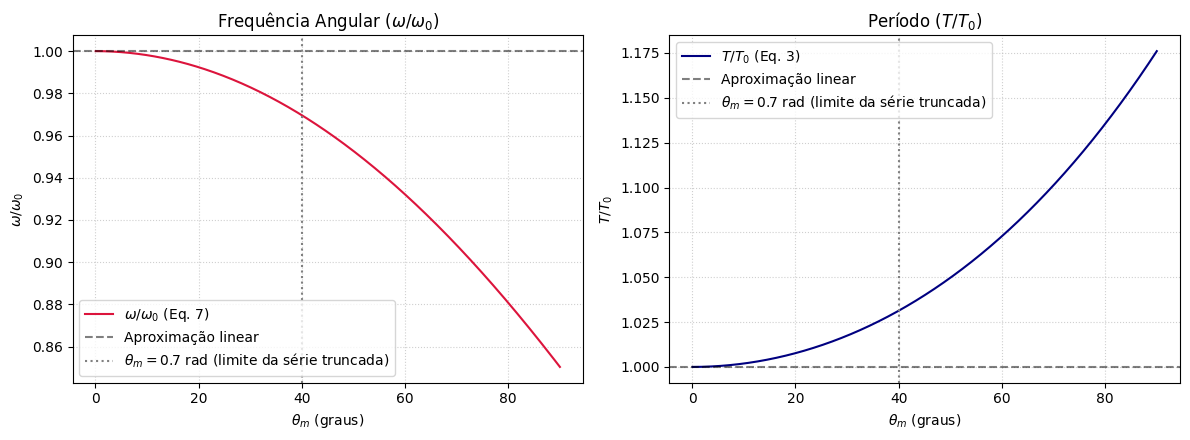

 theta_m (deg)  |  omega/omega_0  |      T/T_0     
---------------------------------------------------
      10       ° |     0.9981      |     1.0019     
      20       ° |     0.9924      |     1.0077     
      30       ° |     0.9829      |     1.0174     
      45       ° |     0.9616      |     1.0399     
      60       ° |     0.9321      |     1.0728     
      90       ° |     0.8503      |     1.1760     


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Intervalo de ângulos iniciais: a Eq. (7) do artigo vale para 0 < theta_m <= pi/2 rad (0 a 90 graus)
theta_m_deg = np.linspace(0.1, 90, 500)
theta_m_rad = np.radians(theta_m_deg)

# Cálculo da frequência omega/omega_0 pela Equação (7)
omega_relativo = 1.0 / (1.0 + (1.0/16.0)*(theta_m_rad**2) + (11.0/3072.0)*(theta_m_rad**4))

# Razão dos períodos T/T_0 (Equação 3)
T_relativo = 1.0 / omega_relativo

# Plotagem dos gráficos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Frequência angular
ax1.plot(theta_m_deg, omega_relativo, color='crimson', label=r'$\omega / \omega_0$ (Eq. 7)')
ax1.axhline(1.0, color='black', linestyle='--', alpha=0.5, label='Aproximação linear')
ax1.axvline(np.degrees(0.7), color='gray', linestyle=':', label=r'$\theta_m = 0.7$ rad (limite da série truncada)')
ax1.set_title(r'Frequência Angular ($\omega / \omega_0$)')
ax1.set_xlabel(r'$\theta_m$ (graus)')
ax1.set_ylabel(r'$\omega / \omega_0$')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# Período
ax2.plot(theta_m_deg, T_relativo, color='navy', label=r'$T / T_0$ (Eq. 3)')
ax2.axhline(1.0, color='black', linestyle='--', alpha=0.5, label='Aproximação linear')
ax2.axvline(np.degrees(0.7), color='gray', linestyle=':', label=r'$\theta_m = 0.7$ rad (limite da série truncada)')
ax2.set_title(r'Período ($T / T_0$)')
ax2.set_xlabel(r'$\theta_m$ (graus)')
ax2.set_ylabel(r'$T / T_0$')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

# Exibição de alguns valores de referência
print(f"{'theta_m (deg)':^15} | {'omega/omega_0':^15} | {'T/T_0':^15}")
print("-" * 51)
for ang in [10, 20, 30, 45, 60, 90]:
    rad = np.radians(ang)
    w_rel = 1.0 / (1.0 + (1.0/16.0)*(rad**2) + (11.0/3072.0)*(rad**4))
    t_rel = 1.0 / w_rel
    print(f"{ang:^15}° | {w_rel:^15.4f} | {t_rel:^15.4f}")

## 3. Resolução Numérica da Equação do Pêndulo (Método RK4)

### 3.1 Transformação do Sistema de EDOs
A equação diferencial de segunda ordem do pêndulo não linear (Equação 1 do artigo):

$$\frac{d^2\theta}{dt^2} + \omega_0^2 \sin\theta = 0$$

pode ser convertida em um sistema de duas Equações Diferenciais Ordinárias de primeira ordem definindo a velocidade angular $\Omega = \frac{d\theta}{dt}$ (no código, variável `omega`; não confundir com a frequência fundamental $\omega$ das Equações 6 e 7):

$$\begin{cases}
\frac{d\theta}{dt} = \Omega \\
\frac{d\Omega}{dt} = -\omega_0^2 \sin\theta
\end{cases}$$

com as condições iniciais do artigo: $\theta(0) = \theta_m$ e $\dot\theta(0) = 0$ (pêndulo solto do repouso).

### 3.2 Algoritmo de Runge-Kutta de 4ª Ordem (RK4)
Para resolver numericamente esse sistema, aplica-se o método RK4 iterativamente a cada passo de tempo $\Delta t$, garantindo alta precisão e estabilidade na integração do movimento angular $\theta(t)$ e da velocidade angular $\Omega(t)$.

### 3.3 Parâmetros do artigo e Figuras 1a e 1b
Seguindo o artigo, usa-se $\omega_0 = 1$ rad/s, o que corresponde a $T_0 = 2\pi \approx 6.28$ s, e os dois ângulos da Figura 1a: pequeno ângulo $\theta_m = 0.01$ rad e grande ângulo $\theta_m = 0.78$ rad ($\approx 45^\circ$). Na Figura 1a as amplitudes são normalizadas ($\theta/\theta_m$) e mostra-se um ciclo completo. A Figura 1b é construída com a Equação (3), truncada em três termos, válida para $\theta_m \le 0.7$ rad. O período também é medido diretamente na solução RK4 ($T = 4\,t_{1/4}$, onde $t_{1/4}$ é o instante do primeiro cruzamento por $\theta = 0$) como verificação da Equação (3).

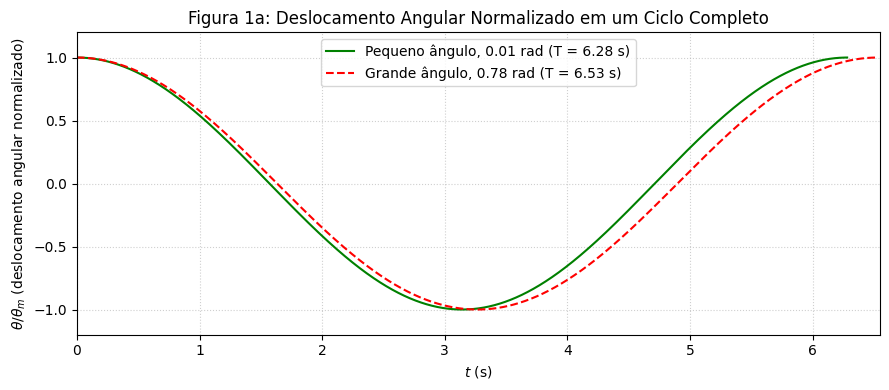

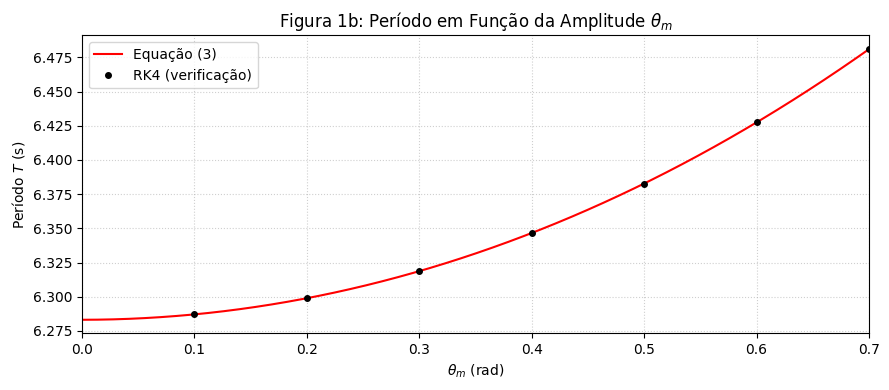

 theta_m (rad)  |  T Eq.(3) (s)   |    T RK4 (s)   
---------------------------------------------------
      0.1       |     6.2871      |     6.2871     
      0.2       |     6.2989      |     6.2989     
      0.3       |     6.3187      |     6.3187     
      0.4       |     6.3466      |     6.3466     
      0.5       |     6.3828      |     6.3828     
      0.6       |     6.4275      |     6.4275     
      0.7       |     6.4810      |     6.4812     


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Sistema de derivadas (Equação 1 do artigo escrita como sistema de 1ª ordem)
def pendulo_derivatives(theta, omega, omega0):
    dtheta_dt = omega
    domega_dt = -(omega0**2) * np.sin(theta)
    return dtheta_dt, domega_dt

# Algoritmo de Runge-Kutta de 4ª Ordem
def rk4_pendulo(theta0, omega0, t_max, dt):
    # N pontos em [0, t_max), t_i = i*dt (evita o erro de arredondamento de np.arange com passo real)
    N = int(round(t_max / dt))
    t = np.arange(N) * dt

    theta = np.zeros(N)
    omega = np.zeros(N)

    # Condição inicial: solto do repouso
    theta[0] = theta0
    omega[0] = 0.0

    for i in range(N - 1):
        k1_th, k1_om = pendulo_derivatives(theta[i], omega[i], omega0)

        k2_th, k2_om = pendulo_derivatives(
            theta[i] + 0.5 * dt * k1_th,
            omega[i] + 0.5 * dt * k1_om,
            omega0
        )

        k3_th, k3_om = pendulo_derivatives(
            theta[i] + 0.5 * dt * k2_th,
            omega[i] + 0.5 * dt * k2_om,
            omega0
        )

        k4_th, k4_om = pendulo_derivatives(
            theta[i] + dt * k3_th,
            omega[i] + dt * k3_om,
            omega0
        )

        theta[i+1] = theta[i] + (dt / 6.0) * (k1_th + 2*k2_th + 2*k3_th + k4_th)
        omega[i+1] = omega[i] + (dt / 6.0) * (k1_om + 2*k2_om + 2*k3_om + k4_om)

    return t, theta, omega

# Período a partir da solução numérica: partindo do repouso em theta_m, o pêndulo
# cruza theta = 0 pela primeira vez em t = T/4 (interpolação linear entre os passos)
def calcular_periodo(t, theta):
    i = np.where((theta[:-1] > 0) & (theta[1:] <= 0))[0][0]
    t_zero = t[i] + (t[i+1] - t[i]) * theta[i] / (theta[i] - theta[i+1])
    return 4.0 * t_zero

# Período pela série de Bernoulli truncada em três termos (Equação 3)
def periodo_eq3(theta_m, T0):
    return T0 * (1.0 + (1.0/16.0)*theta_m**2 + (11.0/3072.0)*theta_m**4)

# Parâmetros de simulação (artigo: omega_0 = 1 rad/s  ->  T_0 = 2*pi ≈ 6.28 s)
omega0 = 1.0
T0 = 2.0 * np.pi / omega0
dt = 0.001
t_max = T0          # um ciclo completo, como na Figura 1a do artigo

# Ângulos de simulação do artigo: pequeno ângulo 0.01 rad e grande ângulo 0.78 rad (≈ 45°)
theta0_1 = 0.01
theta0_2 = 0.78

# Período de 1 ciclo completo para cada ângulo
T1 = periodo_eq3(theta0_1, T0)
T2 = periodo_eq3(theta0_2, T0)

# Execução numérica de 1 ciclo completo para cada ângulo
t1, th1, _ = rk4_pendulo(theta0_1, omega0, T1, dt)
t2, th2, _ = rk4_pendulo(theta0_2, omega0, T2, dt)

# Figura 1a: deslocamento angular normalizado theta(t)/theta_m
plt.figure(figsize=(9, 4))
plt.plot(t1, th1 / theta0_1, label=f'Pequeno ângulo, {theta0_1} rad (T = {T1:.2f} s)', color='green')
plt.plot(t2, th2 / theta0_2, label=f'Grande ângulo, {theta0_2} rad (T = {T2:.2f} s)', color='red', linestyle='--')
plt.title('Figura 1a: Deslocamento Angular Normalizado em um Ciclo Completo')
plt.xlabel('$t$ (s)')
plt.ylabel(r'$\theta/\theta_m$ (deslocamento angular normalizado)')
plt.xlim(0, 6.55)
plt.ylim(-1.2, 1.2)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# Figura 1b: período em função da amplitude pela Equação (3), para 0 <= theta_m <= 0.7 rad
theta_m_vals = np.linspace(0.0, 0.7, 300)
T_eq3 = periodo_eq3(theta_m_vals, T0)

# Verificação: período medido nas soluções RK4 (basta integrar até pouco depois de T/4)
theta_m_rk4 = np.arange(0.1, 0.71, 0.1)
T_rk4 = np.array([calcular_periodo(*rk4_pendulo(th_m, omega0, 0.5 * T0, dt)[:2]) for th_m in theta_m_rk4])

plt.figure(figsize=(9, 4))
plt.plot(theta_m_vals, T_eq3, color='red', label='Equação (3)')
plt.plot(theta_m_rk4, T_rk4, 'ko', markersize=4, label='RK4 (verificação)')
plt.title(r'Figura 1b: Período em Função da Amplitude $\theta_m$')
plt.xlabel(r'$\theta_m$ (rad)')
plt.ylabel('Período $T$ (s)')
plt.xlim(0, 0.7)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

print(f"{'theta_m (rad)':^15} | {'T Eq.(3) (s)':^15} | {'T RK4 (s)':^15}")
print("-" * 51)
for th_m, T_num in zip(theta_m_rk4, T_rk4):
    print(f"{th_m:^15.1f} | {periodo_eq3(th_m, T0):^15.4f} | {T_num:^15.4f}")

## 4. Análise de Fourier e Decomposição em Harmônicos

### 4.1 Transformada Rápida de Fourier (FFT)
Para analisar o conteúdo de frequências do sinal angular $\theta(t)$, aplica-se a Transformada Rápida de Fourier para sinais reais (`numpy.fft.rfft`) aos coeficientes da série de Fourier (Equação 6 do artigo):

$$s(\omega t) = a_0 + \sum_{n=1}^{\infty} a_n \cos(n \omega t) + \sum_{n=1}^{\infty} b_n \sin(n \omega t)$$

onde $\omega = 2\pi/T$ é a frequência fundamental do movimento real (Equação 7). Para que cada harmônico $n\omega$ caia exatamente em um índice da FFT, a solução RK4 é amostrada em **exatamente um período** $T$ (medido na própria solução numérica), com $N$ pontos em $[0, T)$. Sendo $X_n$ a saída de `rfft`, os coeficientes da Equação (6) são:

$$a_0 = \frac{\mathrm{Re}(X_0)}{N}, \qquad a_n = \frac{2\,\mathrm{Re}(X_n)}{N}, \qquad b_n = -\frac{2\,\mathrm{Im}(X_n)}{N}$$

Os coeficientes $a_n$ indicam a contribuição de cada harmônico $n$ na composição da onda (com sinal; o módulo $|X_n|$ não distingue $a_n$ de $b_n$). Em pequenas amplitudes ($\theta_m = 0.01$ rad), o sinal é essencialmente um cosseno puro e $a_1 = \theta_m$ (Equação 5). Com o aumento de $\theta_m$, $a_1$ se afasta de $\theta_m$ (desvio dado pela Equação 8) e surgem os harmônicos ímpares superiores ($a_3$, $a_5$, ...). A seguir são calculados os coeficientes para os ângulos da Figura 1 e para $\theta_m = 0.1, \dots, 1.7$ rad, reproduzindo a Tabela 1 e a Figura 2 do artigo.

Período numérico: T(0.01 rad) = 6.2832 s | T(0.78 rad) = 6.5308 s
Máximo |b_n| (termos de seno nulos): 2.37e-14 (0.01 rad) | 1.55e-12 (0.78 rad)

 Harmônico (n)  |  |a_n| (0.01 rad)  |  |a_n| (0.78 rad)  | a_n c/ sinal (0.78 rad)
----------------------------------------------------------------------------------
       0        |     7.5431e-15     |     4.9099e-13     |       4.9099e-13       
       1        |     1.0000e-02     |     7.8255e-01     |       7.8255e-01       
       2        |     5.0350e-15     |     3.3493e-13     |       -3.3493e-13      
       3        |     5.2084e-09     |     2.5698e-03     |       -2.5698e-03      
       4        |     1.0053e-15     |     6.1380e-14     |       -6.1379e-14      
       5        |     5.5116e-15     |     1.5043e-05     |       1.5043e-05       
       6        |     4.3086e-16     |     2.7170e-14     |       -2.7170e-14      
       7        |     3.1493e-16     |     1.0483e-07     |       -1.0483e-07      

COMPARAÇÃO: Sé

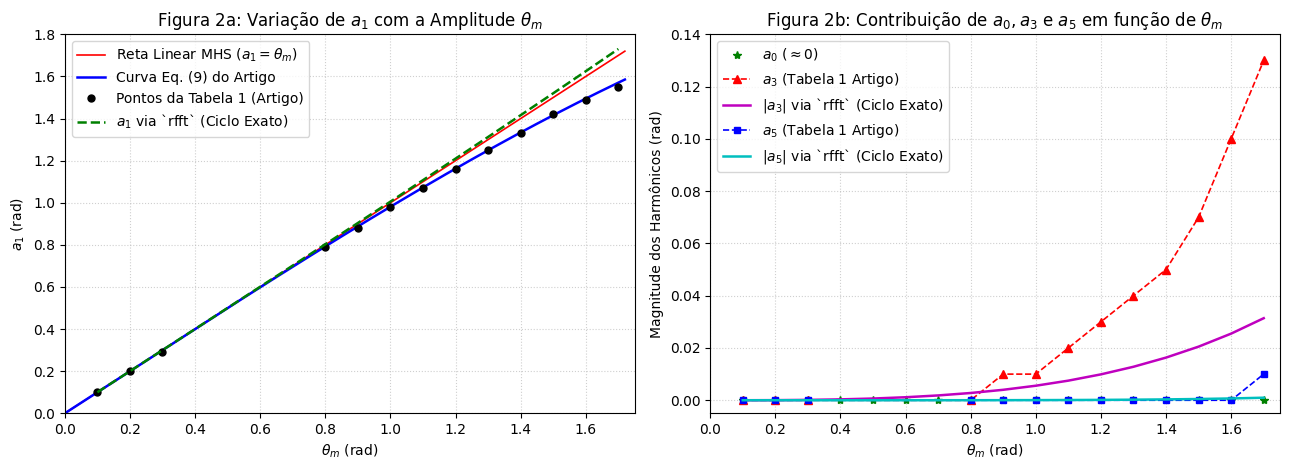

In [4]:
# Cálculo dos coeficientes de Fourier via numpy.fft.rfft sobre exatamente 1 período T
def coeficientes_fourier_rfft(theta_m, omega0=1.0, N=4096):
    T0 = 2.0 * np.pi / omega0
    # Integra até passar de T/4 para medir o período numérico exato T do ciclo
    t_aux, th_aux, _ = rk4_pendulo(theta_m, omega0, 1.2 * T0, 0.0005)
    T = calcular_periodo(t_aux, th_aux)

    # Amostra N pontos exatos em [0, T)
    dt_ciclo = T / N
    t, theta, _ = rk4_pendulo(theta_m, omega0, T, dt_ciclo)
    theta = theta[:N]

    # Transformada Rápida de Fourier para sinais reais
    X = np.fft.rfft(theta)

    # Coeficientes com sinal (série exata de Jacobi) e em módulo (espectro de amplitude)
    a_n = (2.0 / N) * np.real(X)
    a_n[0] = np.real(X[0]) / N
    b_n = -(2.0 / N) * np.imag(X)
    mag_n = (2.0 / N) * np.abs(X)
    mag_n[0] = np.abs(X[0]) / N

    return T, a_n, b_n, mag_n

# 1) Comparação dos harmônicos para os dois ângulos da Figura 1 (0.01 rad e 0.78 rad)
T_001, a_001, b_001, mag_001 = coeficientes_fourier_rfft(0.01)
T_078, a_078, b_078, mag_078 = coeficientes_fourier_rfft(0.78)

print(f"Período numérico: T(0.01 rad) = {T_001:.4f} s | T(0.78 rad) = {T_078:.4f} s")
print(f"Máximo |b_n| (termos de seno nulos): {np.max(np.abs(b_001)):.2e} (0.01 rad) | {np.max(np.abs(b_078)):.2e} (0.78 rad)\n")
print(f"{'Harmônico (n)':^15} | {'|a_n| (0.01 rad)':^18} | {'|a_n| (0.78 rad)':^18} | {'a_n c/ sinal (0.78 rad)':^23}")
print("-" * 82)
for n in range(8):
    print(f"{n:^15d} | {mag_001[n]:^18.4e} | {mag_078[n]:^18.4e} | {a_078[n]:^23.4e}")

# 2) Varredura para reproduzir a Tabela 1 e as Figuras 2a e 2b do artigo (0.1 a 1.7 rad)
theta_m_lista = np.round(np.arange(0.1, 1.75, 0.1), 1)
a0_rfft, a1_rfft, a3_rfft, a5_rfft = [], [], [], []
mag3_rfft, mag5_rfft = [], []

for th_m in theta_m_lista:
    _, a_n, _, mag_n = coeficientes_fourier_rfft(th_m)
    a0_rfft.append(a_n[0])
    a1_rfft.append(a_n[1])
    a3_rfft.append(a_n[3])
    a5_rfft.append(a_n[5])
    mag3_rfft.append(mag_n[3])
    mag5_rfft.append(mag_n[5])

a1_rfft = np.array(a1_rfft)
mag3_rfft = np.array(mag3_rfft)
mag5_rfft = np.array(mag5_rfft)

# Dados da Tabela 1 e Equações (8), (9) e (10) do artigo (Singh, Arun & Lima, 2018)
th_artigo = np.array([0.1, 0.2, 0.3, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7])
a1_artigo = np.array([0.10, 0.20, 0.29, 0.79, 0.88, 0.98, 1.07, 1.16, 1.25, 1.33, 1.42, 1.49, 1.55])
a3_artigo = np.array([0.00, 0.00, 0.00, 0.00, 0.01, 0.01, 0.02, 0.03, 0.04, 0.05, 0.07, 0.10, 0.13])
a5_artigo = np.array([0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.01])
err_artigo = np.array([-0.08, -0.02, 0.05, 1.03, 1.38, 1.77, 2.23, 2.80, 3.41, 4.31, 5.27, 6.65, 8.44])

# Curva analítica da Equação (9) do artigo: a1 = theta_m + 0.0181*theta_m^2 - 0.037*theta_m^3
th_cont = np.linspace(0.0, 1.72, 300)
a1_eq9 = th_cont + 0.0181 * (th_cont**2) - 0.037 * (th_cont**3)

print("\nCOMPARAÇÃO: Série Exata (rfft no período exato) vs. Tabela 1 do Artigo (DFS com Eq. 7 truncada)")
print(f"{'theta_m':^7} | {'a1 (rfft)':^9} | {'a3 (rfft)':^9} | {'a5 (rfft)':^9} || {'a1 (Art.)':^9} | {'a3 (Art.)':^9} | {'a5 (Art.)':^9} | {'Err Art.(%)':^11}")
print("-" * 88)
for i, th in enumerate(th_artigo):
    idx = int(round(th * 10)) - 1
    print(f"{th:^7.1f} | {a1_rfft[idx]:^9.4f} | {a3_rfft[idx]:^9.4f} | {a5_rfft[idx]:^9.5f} || {a1_artigo[i]:^9.2f} | {a3_artigo[i]:^9.2f} | {a5_artigo[i]:^9.2f} | {err_artigo[i]:^11.2f}")

# Reprodução das Figuras 2(a) e 2(b) do artigo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

# Figura 2(a)
ax1.plot(th_cont, th_cont, 'r-', linewidth=1.2, label=r'Reta Linear MHS ($a_1 = \theta_m$)')
ax1.plot(th_cont, a1_eq9, 'b-', linewidth=1.8, label='Curva Eq. (9) do Artigo')
ax1.plot(th_artigo, a1_artigo, 'ko', markersize=5, label='Pontos da Tabela 1 (Artigo)')
ax1.plot(theta_m_lista, a1_rfft, 'g--', linewidth=1.8, label=r'$a_1$ via `rfft` (Ciclo Exato)')
ax1.set_title(r'Figura 2a: Variação de $a_1$ com a Amplitude $\theta_m$')
ax1.set_xlabel(r'$\theta_m$ (rad)')
ax1.set_ylabel(r'$a_1$ (rad)')
ax1.set_xlim(0, 1.75)
ax1.set_ylim(0, 1.80)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# Figura 2(b)
ax2.plot(theta_m_lista, np.zeros_like(theta_m_lista), 'g*', markersize=6, label=r'$a_0$ ($\approx 0$)')
ax2.plot(th_artigo, a3_artigo, 'r^--', linewidth=1.2, markersize=6, label=r'$a_3$ (Tabela 1 Artigo)')
ax2.plot(theta_m_lista, mag3_rfft, 'm-', linewidth=1.8, label=r'$|a_3|$ via `rfft` (Ciclo Exato)')
ax2.plot(th_artigo, a5_artigo, 'bs--', linewidth=1.2, markersize=5, label=r'$a_5$ (Tabela 1 Artigo)')
ax2.plot(theta_m_lista, mag5_rfft, 'c-', linewidth=1.8, label=r'$|a_5|$ via `rfft` (Ciclo Exato)')
ax2.set_title(r'Figura 2b: Contribuição de $a_0, a_3$ e $a_5$ em função de $\theta_m$')
ax2.set_xlabel(r'$\theta_m$ (rad)')
ax2.set_ylabel(r'Magnitude dos Harmônicos (rad)')
ax2.set_xlim(0, 1.75)
ax2.set_ylim(-0.005, 0.14)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

### 4.2 Discussão dos resultados

- **$b_n = 0$**: todos os coeficientes de seno são nulos (da ordem de $10^{-11}$, erro numérico), confirmando que a solução da Equação (1) com $\theta(0) = \theta_m$ e $\dot\theta(0) = 0$ é uma função par, como afirma o artigo.
- **Harmônicos pares nulos**: $a_0, a_2, a_4, \dots \approx 0$, de modo que só os harmônicos ímpares contribuem.
- **Pequenos ângulos**: para $\theta_m = 0.01$ rad tem-se $a_1 = \theta_m$ e $a_3 \sim 10^{-9}$, isto é, o movimento é o MHS da Equação (5).
- **Grandes ângulos**: $a_1$ se afasta de $\theta_m$ e $a_3$, $a_5$ crescem rapidamente com $\theta_m$ ($|a_3| \approx 0.03$ e $a_5 \approx 0.001$ rad em $\theta_m = 1.7$ rad). Mesmo em $\theta_m = 1.7$ rad, $a_1$ concentra mais de 98% da amplitude: o pêndulo **não** é fortemente anarmônico, que é a conclusão principal do artigo.
- **Consistência**: em todos os casos $a_0 + a_1 + a_3 + a_5 = \theta(0) = \theta_m$, e o período medido no RK4 coincide com a Equação (3) até $\theta_m \approx 0.7$ rad.

**Comparação com a Tabela 1 do artigo.** O comportamento qualitativo é o mesmo (somente $a_1$, $a_3$ e $a_5$ relevantes, desvio crescente com $\theta_m$, $b_n = 0$), mas os valores numéricos diferem: aqui obtém-se $a_1$ ligeiramente **maior** que $\theta_m$ e $a_3$ **negativo** (Err de $-0.35\%$ em 0.8 rad e $-1.79\%$ em 1.7 rad), enquanto a Tabela 1 traz $a_1 < \theta_m$ e $a_3 > 0$ (Err de $1.03\%$ e $8.44\%$). O cálculo aqui segue a definição da Equação (6), com $\omega$ igual à frequência fundamental do movimento e amostragem de um período inteiro. Os dados do próprio artigo não permitem localizar a origem da diferença, porque o código de DFS (Apêndice B) não foi fornecido. Por isso, as curvas das Equações (9) e (10), que são ajustes dos dados do artigo, aparecem na Figura 2a apenas como referência.

## 5. Equação (11) e Generalização para Qualquer Pêndulo

### 5.1 Como a Equação (11) é obtida
Partindo da série (6) e dos resultados da Seção 4:

1. Como $\theta(0) = \theta_m$ e $\dot\theta(0) = 0$, a solução da Equação (1) é uma função **par**, logo todos os $b_n = 0$.
2. Com as condições mistas $\theta(0) = \theta_m$ e $d\theta/dt = 0$ em $\theta = \theta_m$ (argumento de Simon e Kreyszig citado no artigo), os termos pares se anulam: $a_0 = a_2 = a_4 = \dots = 0$, restando apenas os harmônicos ímpares.
3. Os coeficientes ímpares decaem rapidamente com $n$, de modo que a série pode ser truncada em $n = 5$:

$$\theta(t) \approx a_1 \cos(\omega t) + a_3 \cos(3\omega t) + a_5 \cos(5\omega t) \qquad (11)$$

### 5.2 Por que a Equação (11) descreve qualquer pêndulo
Os coeficientes $a_n$ são funções **apenas de $\theta_m$**, com $a_1(\theta_m \to 0) = \theta_m$, $a_3(\theta_m \to 0) = 0$ e $a_5(\theta_m \to 0) = 0$. De fato, escrevendo a Equação (1) em termos de $\tau = \omega_0 t$ obtém-se $d^2\theta/d\tau^2 = -\sin\theta$, que não contém $g$ nem $L$. Assim, o comprimento e a gravidade só alteram a escala de tempo: para descrever um pêndulo qualquer basta conhecer $a_1, a_3, a_5$ para a amplitude $\theta_m$ (Tabela 1) e a frequência fundamental $\omega$ dada pela Equação (7) com $\omega_0 = \sqrt{g/L}$ do pêndulo em questão.

A célula abaixo (a) compara a Equação (11) com a solução RK4 da Equação (1) e (b) mostra que pêndulos de comprimentos diferentes, com a mesma $\theta_m$, possuem os mesmos coeficientes $a_n$, sendo todos descritos pela Equação (11) com os coeficientes calculados para $\omega_0 = 1$ rad/s.

Coeficientes universais para theta_m = 1.5 rad:
a1 = 1.5200 rad | a3 = -0.0205 rad | a5 = 0.00048 rad



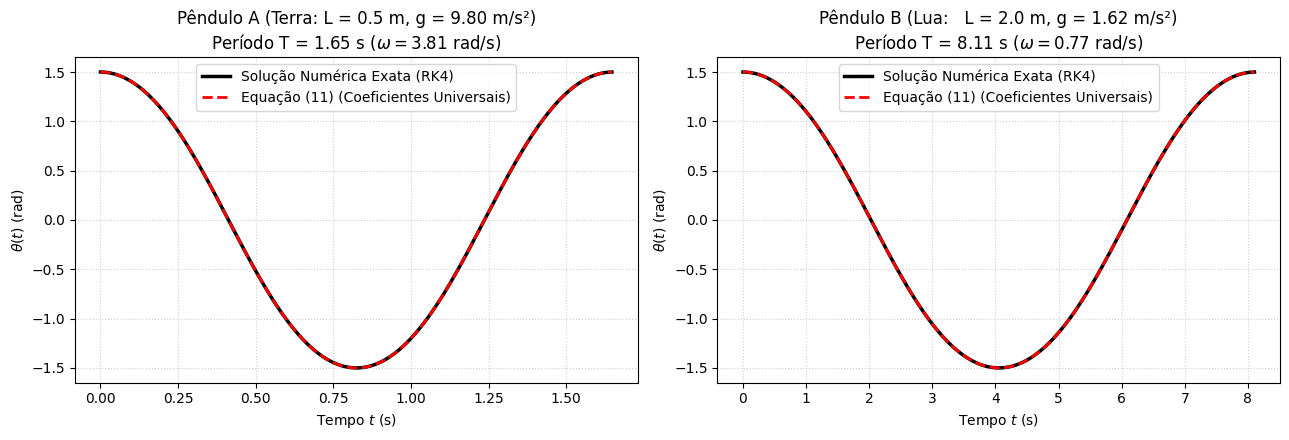

In [5]:
# Demonstração prática da Seção 5.2 (Questão 5):
# Testando a Equação (11) em dois pêndulos diferentes soltos do mesmo ângulo inicial theta_m = 1.5 rad (~86°)
theta_m_teste = 1.5

# 1. Extrai os coeficientes universais a_1, a_3, a_5 usando a função definida na Seção 4 (com omega0 = 1.0)
_, an_univ, _, _ = coeficientes_fourier_rfft(theta_m_teste, omega0=1.0)
a1_u, a3_u, a5_u = an_univ[1], an_univ[3], an_univ[5]

print(f"Coeficientes universais para theta_m = {theta_m_teste} rad:")
print(f"a1 = {a1_u:.4f} rad | a3 = {a3_u:.4f} rad | a5 = {a5_u:.5f} rad\n")

# 2. Define dois pêndulos fisicamente muito distintos:
# Pêndulo A: na Terra (L = 0.5 m, g = 9.80 m/s²)
# Pêndulo B: na Lua   (L = 2.0 m, g = 1.62 m/s²)
casos = [
    ("Pêndulo A (Terra: L = 0.5 m, g = 9.80 m/s²)", 0.5, 9.80),
    ("Pêndulo B (Lua:   L = 2.0 m, g = 1.62 m/s²)", 2.0, 1.62)
]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, (titulo, L_p, g_p) in zip(axes, casos):
    # Frequência natural e período linear do pêndulo específico
    w0_p = np.sqrt(g_p / L_p)
    T0_p = 2.0 * np.pi / w0_p

    # Simulação RK4 auxiliar para medir o período real T_p deste pêndulo (usando as funções da Seção 3)
    t_aux, th_aux, _ = rk4_pendulo(theta_m_teste, w0_p, 1.2 * T0_p, T0_p / 4000.0)
    T_p = calcular_periodo(t_aux, th_aux)
    w_p = 2.0 * np.pi / T_p

    # Solução numérica direta da Equação (1) via RK4 para 1 ciclo completo deste pêndulo
    t_p, theta_rk4_p, _ = rk4_pendulo(theta_m_teste, w0_p, T_p, T_p / 1000.0)

    # Reconstrução analítica pela Equação (11) usando os MESMOS coeficientes universais a1, a3, a5
    theta_eq11_p = (
        a1_u * np.cos(w_p * t_p)
        + a3_u * np.cos(3.0 * w_p * t_p)
        + a5_u * np.cos(5.0 * w_p * t_p)
    )

    # Plotagem comparativa
    ax.plot(t_p, theta_rk4_p, 'k-', linewidth=2.5, label='Solução Numérica Exata (RK4)')
    ax.plot(t_p, theta_eq11_p, 'r--', linewidth=2.0, label='Equação (11) (Coeficientes Universais)')
    ax.set_title(f"{titulo}\nPeríodo T = {T_p:.2f} s ($\\omega = {w_p:.2f}$ rad/s)")
    ax.set_xlabel('Tempo $t$ (s)')
    ax.set_ylabel(r'$\theta(t)$ (rad)')
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend()

plt.tight_layout()
plt.show()